In [1]:
# 4.1 读取 CSV，按 NCEI 数据说明清洗缺失值和质量不足的观测
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from IPython.display import display

# 从作业目录或它的子目录运行时，自动找到原始数据。
base = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "GSOD_Guangdong_2015_2024").is_dir())
file = base / "GSOD_Guangdong_2015_2024" / "guangdong_gsod_2015_2024_raw_merged.csv"
stations = {"59287099999": "广州白云", "59493099999": "深圳宝安",
            "59082099999": "韶关", "59316099999": "潮汕/汕头", "59658099999": "湛江"}
df = pd.read_csv(file, dtype={"STATION": "string", "FRSHTT": "string"})
df["DATE"] = pd.to_datetime(df["DATE"], errors="coerce")
df = df[df["STATION"].isin(stations) & df["DATE"].between("2015-01-01", "2024-12-31")].copy()
if df.duplicated(["STATION", "DATE"]).any():
    raise ValueError("发现重复站点日期，请先检查原始数据。")

# 官方缺失码：能见度、风速 999.9；气温、露点 9999.9。
# *_ATTRIBUTES 是该日平均值的观测次数；本作业要求每个变量至少 4 次。
specs = {"VISIB": (999.9, "vis_km"), "WDSP": (999.9, "wind_ms"),
         "TEMP": (9999.9, "temp_c"), "DEWP": (9999.9, "dewpoint_c")}
for field, (missing, output) in specs.items():
    values = pd.to_numeric(df[field], errors="coerce")
    counts = pd.to_numeric(df[field + "_ATTRIBUTES"], errors="coerce")
    valid = values.notna() & np.isfinite(values) & values.ne(missing) & counts.ge(4)
    if field in ("VISIB", "WDSP"):
        valid &= values.ge(0)  # 保留可能由四舍五入产生的 0，不保留负值。
    values = values.where(valid)
    if field == "VISIB":
        df[output] = values * 1.609344                # 英里 → km
    elif field == "WDSP":
        df[output] = values * 0.5144444444444445      # 节 → m/s
    else:
        df[output] = (values - 32) * 5 / 9            # 华氏度 → 摄氏度

# 温度露点差越小，空气越接近饱和。负差仅使派生指标缺失，不删除能见度。
gap = df["temp_c"] - df["dewpoint_c"]
df["dewpoint_gap_c"] = gap.where(gap.ge(0))
df["source_present"] = True
calendar = pd.MultiIndex.from_product(
    [list(stations), pd.date_range("2015-01-01", "2024-12-31", freq="D")],
    names=["STATION", "DATE"])
df = df.set_index(["STATION", "DATE"]).reindex(calendar).reset_index()
df["source_present"] = df["source_present"].fillna(False).astype(bool)
df["station"] = df["STATION"].map(stations)
# 补齐的是日期，缺失值保持 NaN；不补零、不插值。DATE 是 UTC 日统计。
coverage = df.groupby("station").agg(日历日数=("DATE", "size"), 原始记录数=("source_present", "sum"),
                                     有效能见度日数=("vis_km", "count"))
coverage["有效率_%"] = (coverage["有效能见度日数"] / coverage["日历日数"] * 100).round(2)
print("4.1 清洗后的数据覆盖情况：")
display(coverage)


4.1 清洗后的数据覆盖情况：


,日历日数,原始记录数,有效能见度日数,有效率_%
station,,,,
广州白云,3653,3640,3595,98.41
深圳宝安,3653,3639,3639,99.62
湛江,3653,3556,3481,95.29
潮汕/汕头,3653,3640,3640,99.64
韶关,3653,3606,3606,98.71


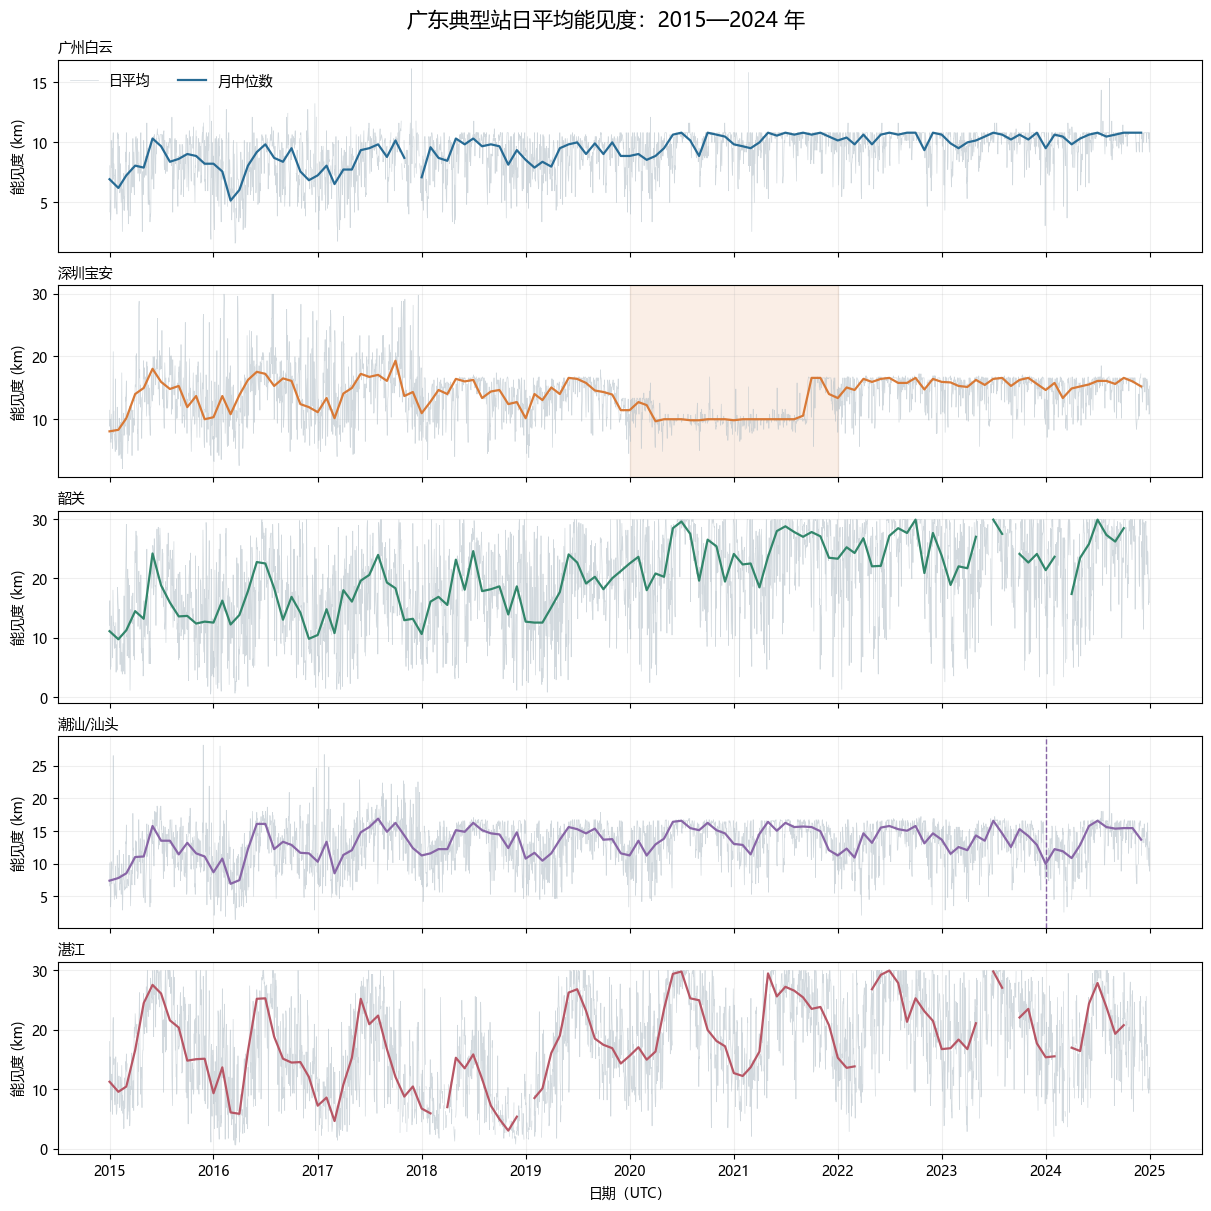

阴影：深圳 2020—2021 年有较多固定报告值；虚线：潮汕站 2024 年坐标字段变化。


In [2]:
# 4.2 绘制五站 2015—2024 年能见度时间序列
from matplotlib import font_manager
from matplotlib.font_manager import FontProperties

font_path = Path("C:/Windows/Fonts/msyh.ttc")
if font_path.exists():
    font_manager.fontManager.addfont(str(font_path))
    plt.rcParams["font.family"] = FontProperties(fname=str(font_path)).get_name()
plt.rcParams["axes.unicode_minus"] = False

monthly_parts = []
fig, axes = plt.subplots(5, 1, figsize=(12, 12), sharex=True, layout="constrained")
colors = ["#276B94", "#D87936", "#32866B", "#8865A6", "#B75665"]
for ax, (station_id, name), color in zip(axes, stations.items(), colors):
    daily = df[df["STATION"].eq(station_id)].set_index("DATE")
    m = daily["vis_km"].resample("MS").agg(["count", "median"])
    # 当月有效天数至少占实际日历天数的 80%，才保留月中位数。
    m["median"] = m["median"].where(m["count"] / m.index.days_in_month >= 0.8)
    m["STATION"] = station_id
    monthly_parts.append(m.reset_index())
    ax.plot(daily.index, daily["vis_km"], color="#AEBBC4", lw=0.5, alpha=0.55, label="日平均")
    ax.plot(m.index, m["median"], color=color, lw=1.6, label="月中位数")
    ax.set_title(name, loc="left", fontsize=10)
    ax.set_ylabel("能见度 (km)")
    ax.grid(alpha=0.2)
    if station_id == "59493099999":
        ax.axvspan(pd.Timestamp("2020-01-01"), pd.Timestamp("2022-01-01"), color="#D87936", alpha=.12)
    if station_id == "59316099999":
        ax.axvline(pd.Timestamp("2024-01-01"), color="#8865A6", ls="--", lw=1)
monthly = pd.concat(monthly_parts, ignore_index=True)
axes[0].legend(frameon=False, ncol=2, loc="upper left")
axes[-1].set_xlabel("日期（UTC）")
fig.suptitle("广东典型站日平均能见度：2015—2024 年", fontsize=15)
plt.show()
print("阴影：深圳 2020—2021 年有较多固定报告值；虚线：潮汕站 2024 年坐标字段变化。")


In [3]:
# 4.3 至少五项统计检查，并报告实际发现
# 检查 1—4：均值、中位数、标准差、四分位距；另计算低能见度日频率。
summary = df.groupby("STATION")["vis_km"].agg(有效日数="count", 平均值_km="mean",
                                             中位数_km="median", 标准差_km="std")
q = df.groupby("STATION")["vis_km"].quantile([.25, .75]).unstack()
summary["四分位距_km"] = q[0.75] - q[0.25]
# 5 km 是本作业的分析阈值，不等同于霾日的正式定义；分母只包括有效日。
summary["低于5km_%"] = df.groupby("STATION")["vis_km"].apply(
    lambda s: s.dropna().lt(5).mean() * 100)

# 检查 5：每个日历月跨年取合格月中位数的中位数，找出最高/最低月份。
monthly["month"] = monthly["DATE"].dt.month
season = monthly.groupby(["STATION", "month"])["median"].median().unstack()
summary["最高月份"] = season.idxmax(axis=1)
summary["最低月份"] = season.idxmin(axis=1)
summary["月季节差_km"] = season.max(axis=1) - season.min(axis=1)

# 检查 6：月中位数对时间和月份虚拟变量做线性拟合，估计描述性斜率。
# 不在这个简版中计算 p 值；10 年趋势和报告方式可能影响解释。
slopes = {}
for station_id in stations:
    m = monthly[monthly["STATION"].eq(station_id)].dropna(subset=["median"])
    t = m["DATE"].dt.year.to_numpy() - 2015 + (m["month"].to_numpy() - 1) / 12
    month_dummies = pd.get_dummies(pd.Categorical(m["month"], categories=range(1, 13)),
                                   drop_first=True, dtype=float).to_numpy()
    X = np.column_stack([np.ones(len(m)), t, month_dummies])
    slopes[station_id] = np.linalg.lstsq(X, m["median"].to_numpy(), rcond=None)[0][1]
summary["趋势_km_每年"] = pd.Series(slopes)

# 检查 7：分别减去各站对应日历月的平均值，再计算 Spearman 秩相关。
# 使用能见度、温度露点差和风速共同有效的日期；不把相关解释为因果。
correlations = []
for station_id in stations:
    d = df[df["STATION"].eq(station_id)].dropna(subset=["vis_km", "dewpoint_gap_c", "wind_ms"]).copy()
    month = d["DATE"].dt.month
    for col in ["vis_km", "dewpoint_gap_c", "wind_ms"]:
        d[col + "_anom"] = d[col] - d.groupby(month)[col].transform("mean")
    correlations.append({"STATION": station_id, "共同有效日数": len(d),
                         "温度露点差_rho": spearmanr(d["vis_km_anom"], d["dewpoint_gap_c_anom"]).statistic,
                         "风速_rho": spearmanr(d["vis_km_anom"], d["wind_ms_anom"]).statistic})
corr = pd.DataFrame(correlations).set_index("STATION")
summary.index = summary.index.map(stations)
corr.index = corr.index.map(stations)
print("4.3 描述统计、季节变化、趋势和低能见度日频率：")
display(summary.round(2))
print("去除月平均季节循环后的 Spearman 相关系数：")
display(corr.round(2))

# 根据计算结果生成文字发现，而不是预先写死结论。
print(f"发现 1：五站最高月份分别为 {summary['最高月份'].astype(int).tolist()} 月。")
print(f"发现 2：平均能见度最高为 {summary['平均值_km'].idxmax()}，最低为 {summary['平均值_km'].idxmin()}。")
print(f"发现 3：温度露点差的相关系数为 {corr['温度露点差_rho'].min():.2f}—{corr['温度露点差_rho'].max():.2f}。")
print(f"发现 4：风速的相关系数为 {corr['风速_rho'].min():.2f}—{corr['风速_rho'].max():.2f}，站点间强度不同。")
print(f"发现 5：低于 5 km 的有效日比例最高为 {summary['低于5km_%'].idxmax()}（{summary['低于5km_%'].max():.2f}%）。")
print("解释：能见度受湿度、天气和报告方式等影响，不能仅据此推断 PM2.5 或减排成效。")
print("深圳报告值集中及潮汕坐标字段变化限制趋势解读；各站结果不能直接代表广东省平均。")


4.3 描述统计、季节变化、趋势和低能见度日频率：


,有效日数,平均值_km,中位数_km,标准差_km,四分位距_km,低于5km_%,最高月份,最低月份,月季节差_km,趋势_km_每年
STATION,,,,,,,,,,
韶关,3606,19.88,20.60,7.55,12.23,3.61,7,3,9.01,1.38
广州白云,3595,9.16,9.82,1.82,2.41,3.95,7,3,1.93,0.30
潮汕/汕头,3640,13.05,13.68,3.43,4.99,2.12,7,1,5.15,0.26
深圳宝安,3639,13.62,14.16,3.77,6.28,1.07,7,1,5.31,0.16
湛江,3481,17.72,17.86,8.00,13.36,6.00,7,3,14.93,0.89


去除月平均季节循环后的 Spearman 相关系数：


,共同有效日数,温度露点差_rho,风速_rho
STATION,,,
广州白云,3595,0.39,0.45
深圳宝安,3639,0.32,0.04
韶关,3601,0.55,0.44
潮汕/汕头,3640,0.57,0.37
湛江,3453,0.45,0.05


发现 1：五站最高月份分别为 [7, 7, 7, 7, 7] 月。
发现 2：平均能见度最高为 韶关，最低为 广州白云。
发现 3：温度露点差的相关系数为 0.32—0.57。
发现 4：风速的相关系数为 0.04—0.45，站点间强度不同。
发现 5：低于 5 km 的有效日比例最高为 湛江（6.00%）。
解释：能见度受湿度、天气和报告方式等影响，不能仅据此推断 PM2.5 或减排成效。
深圳报告值集中及潮汕坐标字段变化限制趋势解读；各站结果不能直接代表广东省平均。
